# Day 2 · Validate honestly before tuning

Goal: audit which features really exist at application time, remove post-outcome leakage and duplicate events, then evaluate *later* requests whose labels have matured while keeping each validation fold's customers out of that fold's training rows. A small hyperparameter search is run and frozen on a separate historical cohort **before** any outer-validation number is read.

## 1.ٍSetup

In [1]:
from pathlib import Path
import hashlib
import importlib.util
import os
import runpy
import signal
import subprocess
import sys
import time
import urllib.error
import urllib.request

RUN_STARTED = time.perf_counter()

COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
LAB_REVISION = "1e1da4acbee8941bef07245b259fb6c27ced4ad7"
SUPPORT_HASHES = {
    "scripts/day2_validation.py": "d2fd0353330c3629bdaed6c570528792955fce232540a85d33532a9432522f43",
    "data/day2_optuna_example.csv": "a59000eee4caced319735d237b8d121b2e0c7384acce93392d214ddbfe2f5b93",
    "data/day2_optuna_example.json": "a91a4d3a39ecd9cbab9bf902aaf5e2e060d4e21bcc93793057d5250aa002802c",
}
RAW_BASE = "https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template"


def running_in_colab():
    try:
        return importlib.util.find_spec("google.colab") is not None
    except ModuleNotFoundError:
        return False


IN_COLAB = running_in_colab()
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
ROOT.mkdir(parents=True, exist_ok=True)

setup_path = ROOT / "scripts" / "setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    for attempt in range(3):
        try:
            with urllib.request.urlopen(f"{RAW_BASE}/{COURSE_REVISION}/scripts/setup_colab.py", timeout=45) as reply:
                payload = reply.read(200_000)
            if hashlib.sha256(payload).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(payload)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry, or upload the unchanged project files.")
            time.sleep(attempt + 1)

prepare = runpy.run_path(str(setup_path))["prepare"]
try:
    environment = prepare(ROOT, COURSE_REVISION, MANIFEST_SHA256)
except RuntimeError as problem:
    if "already imported" not in str(problem):
        raise
    print("Installing the pinned package versions (one time, 1-2 minutes)...", flush=True)
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "--quiet",
         "-r", str(ROOT / "requirements-colab.txt"), "-c", str(ROOT / "constraints.txt")],
        capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError("Package installation failed:\n" + result.stderr[-3000:])
    print("Done. The runtime restarts by itself now (a 'session crashed' notice is expected).\n"
          "After it restarts, choose Runtime > Run all again.", flush=True)
    time.sleep(2)
    os.kill(os.getpid(), signal.SIGKILL)

FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

from setup_colab import fetch_verified

for relative, expected in SUPPORT_HASHES.items():
    fetch_verified(f"{RAW_BASE}/{LAB_REVISION}/{relative}", ROOT / relative, expected)
print("Day 2 setup verified")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Day 2 setup verified


## 2. Leakage and duplicate audit

In [2]:
import json
import platform
import zipfile
from dataclasses import asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from data_checks import validate_frame
from day2_validation import (ValidationConfig, BASE_PARAMS, leakage_audit, deduplicate_applications,
                             make_time_group_split, reserve_tuning_pool, tune_on_reserved_pool,
                             negative_controls, evaluate_outer, summarize_folds, reflection_check)

contract = json.loads((ROOT / "data/data_contract.json").read_text(encoding="utf-8"))
feature_dictionary = pd.read_csv(ROOT / "data/feature_dictionary.csv")
raw_applications = pd.read_csv(ROOT / "data/tamweel_dirty.csv")
validate_frame(raw_applications, contract, "dirty")

audit = leakage_audit(raw_applications, feature_dictionary)
assert not audit.action.eq("BLOCK_UNKNOWN").any(), "Review unknown fields before training."
leaked_features = audit.loc[audit.action.eq("DROP_POST_OUTCOME"), "feature"].tolist()

clean, duplicates = deduplicate_applications(raw_applications.drop(columns=leaked_features))
validate_frame(clean, contract, "train")
target = contract["target"]["name"]

assert FAST_MODE != FULL_MODE, "Choose exactly one mode."
config = ValidationConfig(max_trees=200 if FAST_MODE else 600, trials=8, timeout_seconds=120)
ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)

display(audit)
display(pd.DataFrame([{**duplicates, "predictors": int(audit.action.eq("KEEP").sum()),
                       "positive_rate": clean[target].mean()}]))
print("Removed post-outcome fields:", leaked_features)
print(audit.loc[audit.feature.isin(leaked_features), ["feature", "role", "available_at"]]
      .to_string(index=False))

,feature,role,available_at,action
0,application_id,id,application_date,EXCLUDE_METADATA_OR_TARGET
1,customer_id,id,application_date,EXCLUDE_METADATA_OR_TARGET
2,application_date,split,application_date,EXCLUDE_METADATA_OR_TARGET
3,age,predictor,application_date,KEEP
4,income_sar,predictor,application_date,KEEP
5,loan_amount_sar,predictor,application_date,KEEP
6,tenor_months,predictor,application_date,KEEP
7,bureau_score,predictor,application_date,KEEP
8,dti,predictor,application_date,KEEP
9,months_employed,predictor,application_date,KEEP


,input_rows,retained_rows,duplicate_rows_removed,predictors,positive_rate
0,10000,10000,0,22,0.0789


Removed post-outcome fields: ['days_past_due_60', 'collection_calls']
         feature role      available_at
days_past_due_60 leak after_application
collection_calls leak after_application


## 3. Time, customer and maturity rules

Three forward folds. A training row counts only if its application date + 90 days is before the validation start, and no validation customer may appear in that fold's training rows. The early rows are a warm-up period with no predictions. Look at the fold table and figure before reading any metric.

,fold,validation_start,validation_end_exclusive,train_rows,validation_rows,train_positives,validation_positives,immature_past_rows_removed,customer_overlap_rows_removed,shared_customers,latest_training_label_available,validation_positive_rate
0,1,2023-07-01,2024-01-01,3223,1632,274,110,826,912,0,2023-06-30,0.067402
1,2,2024-01-01,2024-07-01,4460,1674,353,135,785,1348,0,2023-12-31,0.080645
2,3,2024-07-01,2025-01-01,5731,1733,465,139,861,1675,0,2024-06-30,0.080208


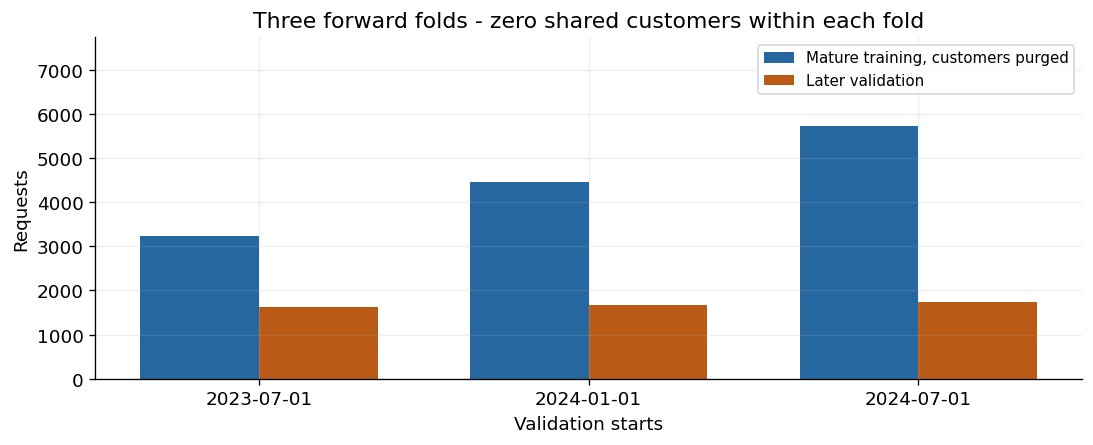

In [3]:
folds = make_time_group_split(clean, horizon_days=contract["target"]["horizon_days"])
fold_audit = pd.DataFrame([item["audit"] for item in folds])

for item in folds:
    train_part, valid_part = clean.loc[item["train"]], clean.loc[item["valid"]]
    start = pd.Timestamp(item["audit"]["validation_start"])
    assert not set(train_part.customer_id) & set(valid_part.customer_id), "customer overlap inside a fold"
    assert (pd.to_datetime(train_part.application_date) + pd.Timedelta(days=90) < start).all(), "immature label"

fold_audit["validation_positive_rate"] = fold_audit.validation_positives / fold_audit.validation_rows
display(fold_audit)

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.2})
fig, ax = plt.subplots(figsize=(9, 3.6), constrained_layout=True)
pos = np.arange(len(fold_audit))
ax.bar(pos - 0.18, fold_audit.train_rows, 0.36, label="Mature training, customers purged", color="#2667A0")
ax.bar(pos + 0.18, fold_audit.validation_rows, 0.36, label="Later validation", color="#BA5A17")
ax.set(xticks=pos, xticklabels=fold_audit.validation_start, ylabel="Requests", xlabel="Validation starts",
       title="Three forward folds - zero shared customers within each fold")
ax.set_ylim(0, fold_audit.train_rows.max() * 1.35)
ax.legend(fontsize=9)
fig.savefig(ARTIFACTS / "day2_fold_sizes.png", dpi=160)
plt.show()

## 4. Reserved search cohort

Tuning uses an older cohort that matured before the first outer fold and excludes every customer from the outer folds. It has its own three folds plus an inner stopping split, so no outer row influences any choice.

The cohort is small with few positives, which is a limitation. The best search AP is a selection number, not a performance estimate.

In [4]:
search_pool = reserve_tuning_pool(clean, folds)
outer_ids = np.concatenate([item["valid"] for item in folds])

assert not set(search_pool.customer_id) & set(clean.loc[outer_ids, "customer_id"])
assert (pd.to_datetime(search_pool.application_date) + pd.Timedelta(days=90) < pd.Timestamp("2023-07-01")).all()

display(pd.DataFrame([{"search_rows": len(search_pool),
                       "search_positives": int(search_pool[target].sum()),
                       "search_positive_rate": search_pool[target].mean(),
                       "latest_application": search_pool.application_date.max(),
                       "outer_validation_rows": len(outer_ids)}]))

,search_rows,search_positives,search_positive_rate,latest_application,outer_validation_rows
0,1935,176,0.090956,2023-04-01,5039


## 5. Bounded Optuna search

Goal: maximise mean AP over three inner folds by tuning only learning rate, leaves and minimum child samples (seed 211, at most 8 trials, at most 120 s). A trial is `COMPLETE`, `PRUNED` or `FAIL`. If none completes, a stored example appears for discussion only and the status becomes `TUNING_REQUIRED`.

,status,completed_trials,attempted_trials,elapsed_seconds,stopping_reason,best_tuning_ap
0,COMPLETE,8,8,5.31147,TRIAL_LIMIT,0.333269


,fold,validation_start,validation_end_exclusive,train_rows,validation_rows,train_positives,validation_positives,immature_past_rows_removed,customer_overlap_rows_removed,shared_customers,latest_training_label_available
0,1,2022-10-01,2023-01-01,703,381,52,42,351,99,0,2022-09-30
1,2,2023-01-01,2023-03-01,1070,271,83,27,373,91,0,2022-12-31
2,3,2023-03-01,2023-04-02,1355,130,118,15,389,61,0,2023-02-28


,trial,state,mean_ap,seconds,learning_rate,num_leaves,min_child_samples,fold_1_ap,fold_2_ap,fold_3_ap
0,0,COMPLETE,0.316524,0.479797,0.085161,15,10,0.319910,0.320935,0.308727
1,1,COMPLETE,0.333269,0.232409,0.085305,31,40,0.391154,0.349373,0.259279
2,2,COMPLETE,0.308752,0.645519,0.034906,31,40,0.404534,0.271448,0.250276
3,3,COMPLETE,0.320550,1.024369,0.040259,31,20,0.384913,0.316815,0.259923
4,4,COMPLETE,0.327798,0.761180,0.062862,15,40,0.403532,0.310814,0.269049
5,5,COMPLETE,0.319093,0.621301,0.037608,7,10,0.365309,0.299275,0.292694
6,6,COMPLETE,0.318537,0.589034,0.039240,15,40,0.414490,0.284021,0.257101
7,7,COMPLETE,0.319024,0.922860,0.062020,31,20,0.376677,0.322038,0.258357


Frozen search parameters: {'learning_rate': 0.08530488562858765, 'num_leaves': 31, 'min_child_samples': 40}


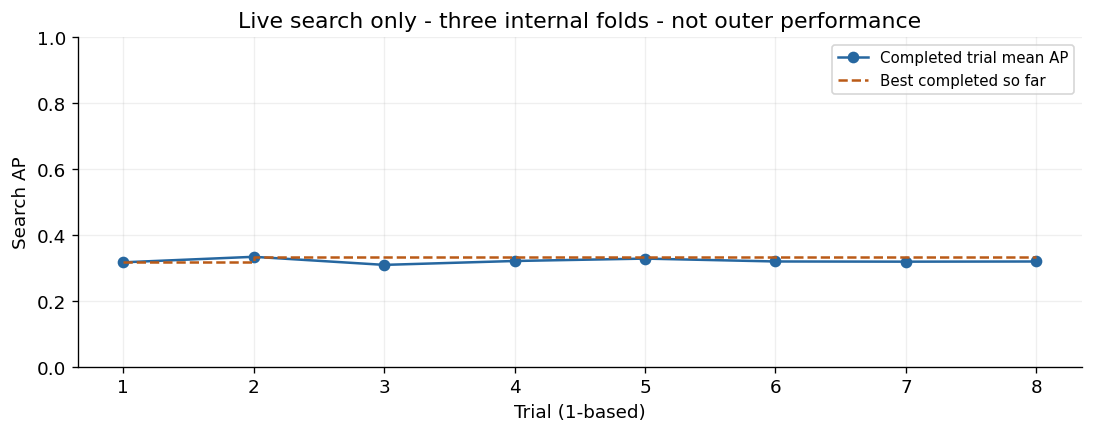

In [5]:
search, history = tune_on_reserved_pool(search_pool, contract, config)
has_tuned = search["best_params"] is not None

summary_keys = ["status", "completed_trials", "attempted_trials", "elapsed_seconds",
                "stopping_reason", "best_tuning_ap"]
display(pd.DataFrame([{key: search[key] for key in summary_keys}]))
display(pd.DataFrame(search["fold_audits"]))
display(history)

if has_tuned:
    print("Frozen search parameters:", search["best_params"])
else:
    example = pd.read_csv(ROOT / "data/day2_optuna_example.csv")
    example_info = json.loads((ROOT / "data/day2_optuna_example.json").read_text(encoding="utf-8"))
    assert example_info["source"] == "EDUCATIONAL_EXAMPLE"
    print("EDUCATIONAL_EXAMPLE - discussion only; not your run or submission. TUNING_REQUIRED.")
    display(example)

fig, ax = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
finished = history[history.state.eq("COMPLETE")]
if len(finished):
    ax.plot(finished.trial + 1, finished.mean_ap, marker="o", color="#2667A0", label="Completed trial mean AP")
    ax.step(finished.trial + 1, finished.mean_ap.cummax(), where="post", color="#BA5A17",
            linestyle="--", label="Best completed so far")
    ax.legend(fontsize=9)
else:
    ax.text(0.5, 0.5, "No completed live trials - rerun needed", transform=ax.transAxes, ha="center")
ax.set(xlabel="Trial (1-based)", ylabel="Search AP", ylim=(0, 1), xticks=range(1, config.trials + 1),
       title="Live search only - three internal folds - not outer performance")
fig.savefig(ARTIFACTS / "day2_search.png", dpi=160)
plt.show()

## 6. Compare after freezing

Four LightGBM protocols, differing only in how the data is handled:

* **Leaky random** - keeps the two post-outcome fields (unsafe)
* **Clean random** - clean fields but mixes time and customers (unsafe)
* **Honest fixed** - forward folds, base settings, 80 trees
* **Honest tuned** - same folds, settings frozen from the search

Random runs cover 10,000 rows and forward runs 5,039, so the gaps are descriptive, not causal.

In [6]:
controls = negative_controls(clean, raw_applications, contract, config)
fixed_report, fixed_oof, fixed_origin = evaluate_outer(
    clean, contract, folds, BASE_PARAMS, config, "clean_time_group_fixed", fixed_trees=80)

reports, prediction_parts, origins = [controls, fixed_report], [fixed_oof], list(fixed_origin)
if has_tuned:
    tuned_report, tuned_oof, tuned_origin = evaluate_outer(
        clean, contract, folds, search["best_params"], config, "clean_time_group_tuned")
    reports.append(tuned_report)
    prediction_parts.append(tuned_oof)
    origins += tuned_origin

validation_report = pd.concat(reports, ignore_index=True)
summary = summarize_folds(validation_report)
oof = pd.concat(prediction_parts, ignore_index=True)
assert not oof.duplicated(["scheme", "application_id"]).any()

display(summary.round(4))
display(validation_report[["scheme", "fold", "roc_auc", "average_precision", "train_rows",
                           "validation_rows", "selected_trees", "shared_customers",
                           "prediction_source"]].round(4))

by_scheme = summary.set_index("scheme")
gap_rows = [
    ("leaky random minus clean random", "leaky_random_control", "clean_random_control"),
    ("clean random minus honest fixed", "clean_random_control", "clean_time_group_fixed"),
    ("honest fixed minus honest reserved search", "clean_time_group_fixed", "clean_time_group_tuned"),
]
gap_table = pd.DataFrame([
    {"comparison": name,
     "ap_gap": by_scheme.loc[a, "ap_mean"] - by_scheme.loc[b, "ap_mean"],
     "roc_auc_gap": by_scheme.loc[a, "roc_auc_mean"] - by_scheme.loc[b, "roc_auc_mean"]}
    for name, a, b in gap_rows if a in by_scheme.index and b in by_scheme.index])
display(gap_table.round(4))
gap_table.to_csv(ARTIFACTS / "day2_gap_check.csv", index=False)   # extra file, not part of the ZIP

,scheme,folds,validation_rows,roc_auc_mean,roc_auc_sd,ap_mean,ap_sd
0,leaky_random_control,3,10000,0.9999,0.0002,0.9988,0.0014
1,clean_random_control,3,10000,0.8010,0.0200,0.3110,0.0293
2,clean_time_group_fixed,3,5039,0.7976,0.0206,0.3153,0.0426
3,clean_time_group_tuned,3,5039,0.7855,0.0232,0.3133,0.0259


,scheme,fold,roc_auc,average_precision,train_rows,validation_rows,selected_trees,shared_customers,prediction_source
0,leaky_random_control,1,0.9996,0.9973,6666,3334,80,1713,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
1,clean_random_control,1,0.7807,0.2776,6666,3334,80,1713,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
2,leaky_random_control,2,0.9999,0.9992,6667,3333,80,1675,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
3,clean_random_control,2,0.8018,0.3232,6667,3333,80,1675,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
4,leaky_random_control,3,1.0000,1.0000,6667,3333,80,1656,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
5,clean_random_control,3,0.8206,0.3321,6667,3333,80,1656,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
6,clean_time_group_fixed,1,0.7948,0.3395,3223,1632,80,0,LIVE_OUT_OF_FOLD
7,clean_time_group_fixed,2,0.8194,0.3403,4460,1674,80,0,LIVE_OUT_OF_FOLD
8,clean_time_group_fixed,3,0.7786,0.2661,5731,1733,80,0,LIVE_OUT_OF_FOLD
9,clean_time_group_tuned,1,0.7826,0.3356,3223,1632,24,0,LIVE_OUT_OF_FOLD


,comparison,ap_gap,roc_auc_gap
0,leaky random minus clean random,0.6879,0.1988
1,clean random minus honest fixed,-0.0044,0.0035
2,honest fixed minus honest reserved search,0.0020,0.0121


### Mean and spread

Each score is the mean of three folds and the bars show the sample standard deviation. The folds are neighbouring periods, so a bar is not a confidence interval. Tiny decimal differences between machines are normal. Do not rerun the search to improve an outer number.

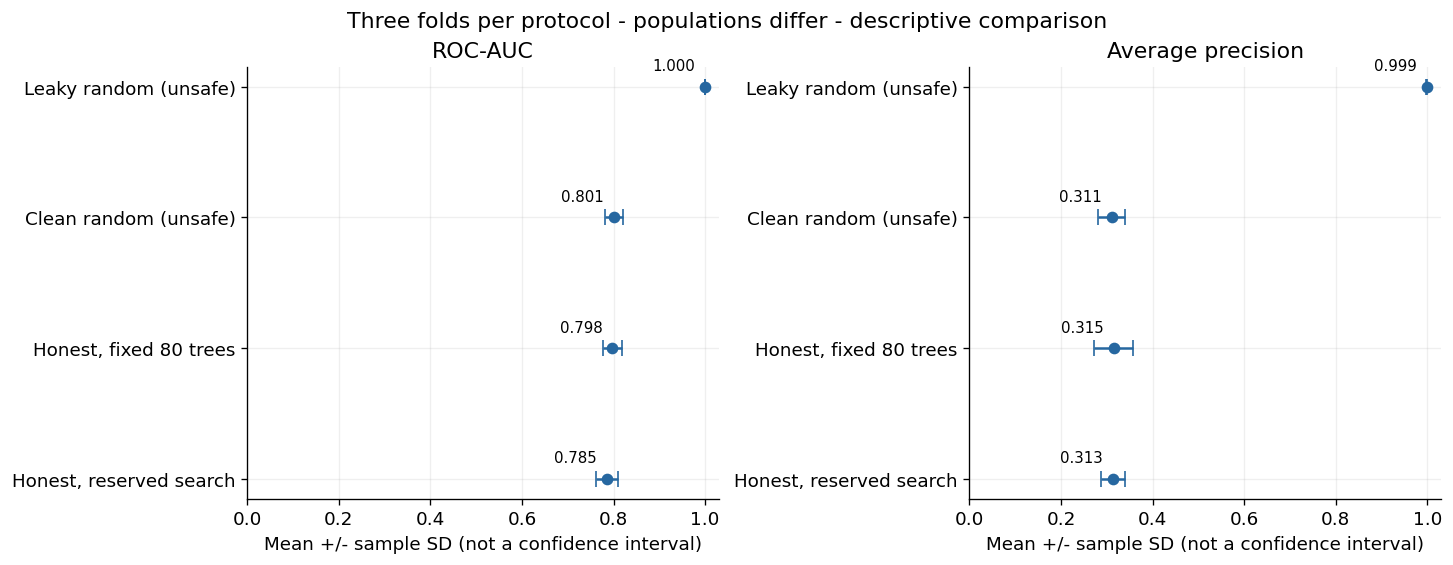

In [7]:
names = {"leaky_random_control": "Leaky random (unsafe)", "clean_random_control": "Clean random (unsafe)",
         "clean_time_group_fixed": "Honest, fixed 80 trees", "clean_time_group_tuned": "Honest, reserved search"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
rows_idx = np.arange(len(summary))
for ax, mean_col, sd_col, title in zip(axes, ["roc_auc_mean", "ap_mean"], ["roc_auc_sd", "ap_sd"],
                                         ["ROC-AUC", "Average precision"]):
    ax.errorbar(summary[mean_col], rows_idx, xerr=summary[sd_col], fmt="o", capsize=5, color="#2667A0")
    ax.set(yticks=rows_idx, yticklabels=[names[s] for s in summary.scheme], xlim=(0, 1.03),
           xlabel="Mean +/- sample SD (not a confidence interval)", title=title)
    ax.invert_yaxis()
    for idx, value in enumerate(summary[mean_col]):
        ax.annotate(f"{value:.3f}", (value, idx), xytext=(-6, 10), textcoords="offset points",
                    ha="right", fontsize=9)
fig.suptitle("Three folds per protocol - populations differ - descriptive comparison")
fig.savefig(ARTIFACTS / "day2_validation_comparison.png", dpi=160)
plt.show()

## 7. Out-of-fold coverage

Each honest protocol gives 5,039 predictions for rows outside that fold's training data. The other 4,961 rows are warm-up and get none (coverage 50.39%). Never fill them with training predictions and never export the leaky predictions.

The last cell shows mean fold AP next to pooled AP; they are different statistics.

In [8]:
coverage = clean[["application_id", "application_date"]].copy()
coverage["role"], coverage["fold"] = "warmup_no_oof", 0
for item in folds:
    coverage.loc[item["valid"], "role"] = "eligible_oof"
    coverage.loc[item["valid"], "fold"] = item["audit"]["fold"]

eligible_ids = set(coverage.loc[coverage.role.eq("eligible_oof"), "application_id"])
for scheme, group in oof.groupby("scheme"):
    assert set(group.application_id) == eligible_ids
    assert group.probability.between(0, 1).all()

display(pd.DataFrame([{"all_rows": len(clean), "eligible_rows": len(eligible_ids),
                       "warmup_without_oof": len(clean) - len(eligible_ids),
                       "whole_data_coverage": len(eligible_ids) / len(clean),
                       "eligible_coverage": 1.0, "live_honest_schemes": oof.scheme.nunique()}]))

from sklearn.metrics import average_precision_score
pooled = pd.DataFrame([
    {"scheme": scheme,
     "mean_fold_ap": by_scheme.loc[scheme, "ap_mean"],
     "pooled_oof_ap": average_precision_score(group[target], group.probability),
     "oof_positive_rate": group[target].mean()}
    for scheme, group in oof.groupby("scheme")])
display(pooled.round(4))

,all_rows,eligible_rows,warmup_without_oof,whole_data_coverage,eligible_coverage,live_honest_schemes
0,10000,5039,4961,0.5039,1.0,2


,scheme,mean_fold_ap,pooled_oof_ap,oof_positive_rate
0,clean_time_group_fixed,0.3153,0.3091,0.0762
1,clean_time_group_tuned,0.3133,0.3041,0.0762


## 8. Written reasoning (legacy fields)

The five `responses` fields are kept for compatibility. Today's official answer is the README question, so they stay empty and the status reads `LEARNER_WORK_REQUIRED`. The check only detects empty fields.

In [9]:
responses = {"leak_example": "", "split_reason": "", "observed_gap": "",
             "imputer_reason": "", "limitations": ""}
checkpoint = reflection_check(responses)
print(checkpoint["status"])
print("Missing:", checkpoint["missing"])

LEARNER_WORK_REQUIRED
Missing: ['leak_example', 'split_reason', 'observed_gap', 'imputer_reason', 'limitations']


## 9. Export

In [10]:
checkpoint = reflection_check(responses)
technical_status = "TECHNICAL_READY" if has_tuned else "TUNING_REQUIRED"

tables = {"validation_report.csv": validation_report, "validation_summary.csv": summary,
          "optuna_results.csv": history, "leakage_audit.csv": audit, "fold_audit.csv": fold_audit,
          "day2_oof_predictions.csv": oof, "day2_oof_coverage.csv": coverage}
for filename, table in tables.items():
    table.to_csv(ARTIFACTS / filename, index=False)

run_info = {
    "technical_status": technical_status, "learner_status": checkpoint["status"],
    "data_revision": COURSE_REVISION, "lab_revision": LAB_REVISION, "support_sha256": SUPPORT_HASHES,
    "data_manifest_sha256": MANIFEST_SHA256,
    "dirty_data_sha256": hashlib.sha256((ROOT / "data/tamweel_dirty.csv").read_bytes()).hexdigest(),
    "config": asdict(config), "mode": "FAST" if FAST_MODE else "FULL", "python": platform.python_version(),
    "duplicates": duplicates, "removed_features": leaked_features,
    "oof_rows_per_scheme": {name: len(group) for name, group in oof.groupby("scheme")},
    "oof_whole_data_coverage": len(eligible_ids) / len(clean), "warmup_rows": len(clean) - len(eligible_ids),
    "search_source": "LIVE", "example_used_for_results": False,
    "challenge_used_for_modeling": False, "grading": "No automatic grade",
}
documents = {"best_params.json": search, "day2_provenance.json": origins,
             "day2_reflection.json": {"responses": responses, "checkpoint": checkpoint},
             "day2_run.json": run_info}
for filename, payload in documents.items():
    (ARTIFACTS / filename).write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8")

bundle_files = (list(tables) + list(documents) +
                ["day2_fold_sizes.png", "day2_search.png", "day2_validation_comparison.png", "environment.json"])
with zipfile.ZipFile(ARTIFACTS / "day2_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in bundle_files:
        assert (ARTIFACTS / filename).is_file(), f"missing {filename}"
        archive.write(ARTIFACTS / filename, arcname=filename)

print(technical_status, "|", checkpoint["status"])
print(f"Saved {len(bundle_files)} files in day2_artifacts.zip. Download it and save this executed notebook.")

TECHNICAL_READY | LEARNER_WORK_REQUIRED
Saved 15 files in day2_artifacts.zip. Download it and save this executed notebook.
